# 01 - Data cleaning and quality

**Goal:** turn the raw hourly readings into two tidy tables (hourly and daily, one row per station and time, one column per pollutant) and document every dropped reading.

**Output:** `data/processed/air_hourly.parquet` and `data/processed/air_daily.parquet`.

## 1. Imports

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from seoul_air import config
from seoul_air.config import POLLUTANTS, STATUS_LABELS
from seoul_air.data import (complete_hourly_grid, daily_means, flag_rate_by_network_level,
                            keep_valid_readings, label_lag_matches, load_api_samples,
                            load_measurements, load_raw, load_stations, network_gap_days,
                            plausible_flagged, to_official_label, to_wide)
from seoul_air.episodes import find_runs
from seoul_air.grades import pm_grade
from seoul_air.report import save_key_figures
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
config.FIGURES.mkdir(parents=True, exist_ok=True)
config.METRICS.mkdir(parents=True, exist_ok=True)

## 2. Load raw files

In [2]:
items = load_raw(config.RAW_FILES["items"])
items

,Item code,Item name,Unit of measurement,Good(Blue),Normal(Green),Bad(Yellow),Very bad(Red)
0,1,SO2,ppm,0.02,0.05,0.15,1.0
1,3,NO2,ppm,0.03,0.06,0.20,2.0
2,5,CO,ppm,2.00,9.00,15.00,50.0
3,6,O3,ppm,0.03,0.09,0.15,0.5
4,8,PM10,Mircrogram/m3,30.00,80.00,150.00,600.0
5,9,PM2.5,Mircrogram/m3,15.00,35.00,75.00,500.0


In [3]:
stations = load_stations()
print(stations.shape)
stations[["station_code", "district", "latitude", "longitude"]].head()

(25, 5)


,station_code,district,latitude,longitude
0,101,Jongno-gu,37.572016,127.005008
1,102,Jung-gu,37.564263,126.974676
2,103,Yongsan-gu,37.540033,127.004850
3,104,Eunpyeong-gu,37.609823,126.934848
4,105,Seodaemun-gu,37.593742,126.949679


In [4]:
long = load_measurements()
print("Shape:", long.shape)
print("Period:", long["datetime"].min(), "to", long["datetime"].max())
print("Stations:", long["station_code"].nunique(), "| Pollutants:", sorted(long["pollutant"].unique()))
long.head()

Shape: (3885066, 6)
Period: 2017-01-01 00:00:00 to 2019-12-31 23:00:00
Stations: 25 | Pollutants: ['co', 'no2', 'o3', 'pm10', 'pm25', 'so2']


,datetime,station_code,item_code,value,status,pollutant
0,2017-01-01,101,1,0.004,0,so2
1,2017-01-01,101,3,0.059,0,no2
2,2017-01-01,101,5,1.200,0,co
3,2017-01-01,101,6,0.002,0,o3
4,2017-01-01,101,8,73.000,0,pm10


**Interpretation.** The data covers 25 stations (one per district) and 6 pollutants, hourly, from 2017-01-01 00:00 to 2019-12-31 23:00.

## 3. Schema, duplicates and timestamps

In [5]:
print(long.dtypes, end="\n\n")
print("Missing values per column:", long.isna().sum().to_dict())
print("Duplicate (datetime, station, pollutant) keys:",
      long.duplicated(["datetime", "station_code", "item_code"]).sum())
print("Hours present:", sorted(long["datetime"].dt.hour.unique().tolist()))

datetime        datetime64[ns]
station_code             int16
item_code                 int8
value                  float64
status                    int8
pollutant             category
dtype: object

Missing values per column: {'datetime': 0, 'station_code': 0, 'item_code': 0, 'value': 0, 'status': 0, 'pollutant': 0}


Duplicate (datetime, station, pollutant) keys: 0
Hours present: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]


**Interpretation.** No missing values in the raw columns, no duplicate keys, and hours run from 0 to 23, so there is no 'hour 24' convention to convert.

### 3.1 What do the timestamps mean?

The Kaggle page says only that each value is a "1 hour average" and does not state the time zone or whether a timestamp marks the start or the end of the hour. Its source, the Seoul Open Data Plaza, follows the Korean convention of labelling an hourly average by the **end** of the hour (AirKorea writes 1 to 24 h; the Seoul Open API writes 00:00 instead of 24:00). Two checks settle how the Kaggle labels relate to it:

1. **Values.** `data/reference/seoul_api_hourly_samples.csv` holds hourly values downloaded from the Seoul Open API (service `TimeAverageAirQuality`, public sample key) for 12 hours of 2017-2019. The same value must appear in the Kaggle file at a fixed offset from the official label.
2. **Publication time.** `data/reference/realtime_label_check.csv` logs the newest label of the real-time service (`RealtimeCityAir`) against the clock. A label that appears as soon as its hour has passed marks the end of that hour.

In [6]:
samples = load_api_samples()
print("Official readings:", len(samples), "| hours:", samples["official_label"].nunique(),
      "| from", samples["official_label"].min(), "to", samples["official_label"].max())
by_hour = pd.DataFrame([
    label_lag_matches(long, group, lags=(-1, 0)).set_index("dataset_hour_minus_official_label")["identical"]
    for _, group in samples.groupby("official_label")
], index=sorted(samples["official_label"].unique()))
# An official label can be compared only if the Kaggle file has the hour before it
comparable = by_hour[by_hour.index - pd.Timedelta(hours=1) >= long["datetime"].min()]
print(f"Hours where the value one hour earlier matches best: {int((comparable[-1] > comparable[0]).sum())} "
      f"of {len(comparable)} comparable hours")
label_lag_matches(long, samples)

Official readings: 360 | hours: 12 | from 2017-01-01 00:00:00 to 2019-12-31 23:00:00


Hours where the value one hour earlier matches best: 11 of 11 comparable hours


,dataset_hour_minus_official_label,compared,identical,identical_%
0,-2,300,84,28.0
1,-1,330,325,98.5
2,0,360,108,30.0
3,1,330,80,24.2
4,2,330,64,19.4


In [7]:
realtime = pd.read_csv(config.REALTIME_LABEL_LOG, parse_dates=["checked_at_utc", "checked_at_kst", "newest_label"])
print("Checks of the newest real-time label:", len(realtime))
(realtime.groupby("newest_label")["checked_at_kst"]
         .agg(first_seen_kst="min", last_seen_kst="max", checks="count"))

Checks of the newest real-time label: 36


,first_seen_kst,last_seen_kst,checks
newest_label,,,
2026-11-09 09:00:00,2026-11-09 09:54:02,2026-11-09 10:22:33,35
2026-11-09 10:00:00,2026-11-09 10:23:24,2026-11-09 10:23:24,1


In [8]:
example = pd.Series(pd.to_datetime(["2017-01-01 00:00", "2019-03-04 07:00", "2019-12-31 23:00"]))
pd.DataFrame({"kaggle_timestamp": example, "covers_from": example, "covers_to": example + pd.Timedelta(hours=1),
              "official_label": to_official_label(example)})

,kaggle_timestamp,covers_from,covers_to,official_label
0,2017-01-01 00:00:00,2017-01-01 00:00:00,2017-01-01 01:00:00,2017-01-01 01:00:00
1,2019-03-04 07:00:00,2019-03-04 07:00:00,2019-03-04 08:00:00,2019-03-04 08:00:00
2,2019-12-31 23:00:00,2019-12-31 23:00:00,2020-01-01 00:00:00,2020-01-01 00:00:00


**Interpretation.** **Start of the hour.** Compared at the same timestamp, only 30.0% of the 360 official values equal the Kaggle value, about what coincidence gives with values that change slowly from hour to hour. Compared with the Kaggle value one hour earlier, 98.5% are identical (325 of 330), and that offset gives the best match in every sampled hour that can be compared, from 2017 to 2019. The Kaggle file therefore holds each official reading one hour before its official label. The real-time service shows what that label means: the label 09:00 was already the newest at 09:54 KST and the label 10:00 appeared only at 10:23 KST, after its hour had ended, so an official label marks the **end** of the hour, and is given in Korean time. Together: a Kaggle timestamp is in **KST** and marks the **start** of the hour it averages (07:00 covers 07:00-08:00). This also explains the period: the official reading labelled 2017-01-01 00:00, which covers the last hour of 2016, is the one hour of the samples absent from the file. **Consequences:** grouping by calendar date of the timestamp gives days of 00:00-24:00, as the official daily means do, so the daily table needs no change; hourly profiles show the hour at which each average starts; and any join with official or weather data must first add one hour (`to_official_label`). **What remains an assumption:** the publication check was made in November 2026, so it assumes the convention of the archive was the same in 2017-2019. The constant offset across the three years supports it, but no document states it. The Kaggle page documents neither point.

## 4. Instrument status

In [9]:
status = long["status"].map(STATUS_LABELS).value_counts().to_frame("readings")
status["share_%"] = (100 * status["readings"] / len(long)).round(2)
status

,readings,share_%
status,,
Normal,3775778,97.19
Under repair,32341,0.83
Needs calibration,29717,0.76
Power cut off,22752,0.59
Abnormal data,20490,0.53
Abnormal,3988,0.10


In [10]:
pd.crosstab(long["pollutant"], long["status"].map(STATUS_LABELS), normalize="index").mul(100).round(2)

status,Abnormal,Abnormal data,Needs calibration,Normal,Power cut off,Under repair
pollutant,,,,,,
co,0.10,0.36,0.81,97.26,0.61,0.87
no2,0.10,0.04,0.79,97.69,0.58,0.81
o3,0.10,0.16,0.78,97.47,0.60,0.89
pm10,0.13,1.38,0.70,96.43,0.57,0.79
pm25,0.12,0.98,0.70,96.86,0.58,0.77
so2,0.08,0.26,0.80,97.41,0.58,0.87


**Interpretation.** 97.19% of the readings have a normal instrument status. The rest are flagged as under repair (0.83%), needing calibration (0.76%), power cut off (0.59%), abnormal data (0.53%) or abnormal (0.10%). PM10 and PM2.5 have the highest share of 'abnormal data' flags (1.38% and 0.98%).

## 5. Why the summary file is not used

`Measurement_summary.csv` is a ready-made wide table, but it has no instrument status column. The check below compares its extreme values with the status recorded in the original file.

In [11]:
cols = ["SO2", "NO2", "O3", "CO", "PM10", "PM2.5"]
summary = load_raw(config.RAW_FILES["summary"], usecols=cols)
print("Summary shape:", summary.shape)
print("Values equal to -1 (missing code):", (summary[cols] == -1).sum().to_dict())
n_summary_extreme = int((summary["PM2.5"] > 500).sum())
print("PM2.5 readings above 500 ug/m3 in the summary file:", n_summary_extreme)

extreme = long[(long["pollutant"] == "pm25") & (long["value"] > 500)]
print("\nStatus of the PM2.5 readings above 500 ug/m3 in the original file:")
print(extreme["status"].map(STATUS_LABELS).value_counts().to_string())
del summary

Summary shape: (647511, 6)
Values equal to -1 (missing code): {'SO2': 3976, 'NO2': 3834, 'O3': 4059, 'CO': 4036, 'PM10': 3962, 'PM2.5': 3973}
PM2.5 readings above 500 ug/m3 in the summary file: 1063

Status of the PM2.5 readings above 500 ug/m3 in the original file:
status
Abnormal data        629
Abnormal             306
Needs calibration    126
Under repair           2


**Interpretation.** The summary file contains 1,063 PM2.5 readings above 500 ug/m3 (the top of the 'Very bad' scale) and uses -1 as a missing code. In the original file, every one of those extreme readings carries a non-normal status (abnormal data, abnormal, needs calibration or under repair). Using the summary file would therefore count readings flagged by the instruments as pollution; filtering on the status removes them without any arbitrary outlier threshold.

## 6. Drop invalid readings

In [12]:
n_raw = len(long)
n_bad_status = int((long["status"] != config.STATUS_NORMAL).sum())
n_negative = int(((long["status"] == config.STATUS_NORMAL) & (long["value"] < 0)).sum())

valid = keep_valid_readings(long)
valid.groupby("pollutant", observed=True)["value"].describe(percentiles=[0.5, 0.99, 0.999]).round(3)

Instrument status not normal: dropped 109,288 rows, 3,775,778 left


Negative value: dropped 0 rows, 3,775,778 left


,count,mean,std,min,50%,99%,99.9%,max
pollutant,,,,,,,,
co,629784.0,0.516,0.240,0.000,0.500,1.300,1.800,3.200
no2,632564.0,0.029,0.016,0.000,0.025,0.074,0.091,0.123
o3,631120.0,0.024,0.019,0.000,0.021,0.084,0.120,0.215
pm10,624408.0,41.799,29.299,1.000,35.000,146.000,237.000,470.000
pm25,627158.0,24.081,18.847,1.000,19.000,95.000,145.000,205.000
so2,630744.0,0.004,0.002,0.001,0.004,0.009,0.013,0.041


**Interpretation.** Keeping only normal-status readings drops 109,288 readings (2.81%); no negative value remains after that filter, so the second rule drops 0. The remaining values are physically plausible: hourly PM2.5 ranges from 1 to 205 ug/m3 and PM10 from 1 to 470 ug/m3, with 99.9th percentiles of 145 and 237. High values with a normal status are kept, because nothing in the data marks them as errors; notebook 04 studies the episodes.

## 7. Does the status filter remove real peaks?

If the filter were discarding real pollution, flagged readings would become more frequent when the air is worse. The check compares each reading with the **network level**: the median of the normal readings of the same hour across all stations. A flagged reading within a factor of 2 of that level is counted as *plausibly real* (a heuristic).

In [13]:
levels = {
    "pm25": ([0, 15, 35, 75, 150, np.inf], ["0-15", "16-35", "36-75", "76-150", "151+"]),
    "pm10": ([0, 30, 80, 150, 300, np.inf], ["0-30", "31-80", "81-150", "151-300", "301+"]),
}
tables = []
for pollutant, (bins, labels) in levels.items():
    table = flag_rate_by_network_level(long[long["pollutant"] == pollutant], bins, labels)
    table.insert(0, "pollutant", pollutant)
    tables.append(table)
pd.concat(tables, ignore_index=True)

,pollutant,network_level,readings,flagged,plausible_flagged,flagged_%
0,pm25,0-15,237890,9062,1745,3.81
1,pm25,16-35,294839,8366,2607,2.84
2,pm25,36-75,100632,2504,1021,2.49
3,pm25,76-150,13950,420,149,3.01
4,pm25,151+,200,1,0,0.50
5,pm25,No reference,0,0,0,NaN
6,pm10,0-30,262889,11943,4070,4.54
7,pm10,31-80,335660,10022,3777,2.99
8,pm10,81-150,44287,1095,356,2.47
9,pm10,151-300,4525,41,6,0.91


In [14]:
# Sensitivity: restore the plausible PM2.5 readings and recompute the daily means
pm25 = long[long["pollutant"] == "pm25"]
is_normal = pm25["status"] == config.STATUS_NORMAL
base = daily_means(to_wide(pm25[is_normal]), ["pm25"])
restored = daily_means(to_wide(pm25[is_normal | plausible_flagged(pm25)]), ["pm25"])
both = base.merge(restored, on=["station_code", "date"], how="outer", suffixes=("_base", "_restored"))

both_valid = both.dropna(subset=["pm25_base", "pm25_restored"])
grade_base = pm_grade(both_valid["pm25_base"].round(), "pm25")
grade_restored = pm_grade(both_valid["pm25_restored"].round(), "pm25")
bad_labels = ["Bad", "Very bad"]
print("Station-days valid in both versions:", f"{len(both_valid):,}")
print("Grade changes:", int((grade_base != grade_restored).sum()))
print("Largest change of a daily mean (ug/m3):",
      round((both_valid["pm25_restored"] - both_valid["pm25_base"]).abs().max(), 2))
print("Bad-or-worse station-days:", int(grade_base.isin(bad_labels).sum()), "->",
      int(grade_restored.isin(bad_labels).sum()))
print("Station-days that become valid:", int((both["pm25_base"].isna() & both["pm25_restored"].notna()).sum()))
del base, restored, both, both_valid

Station-days valid in both versions: 26,247
Grade changes: 83
Largest change of a daily mean (ug/m3): 8.65
Bad-or-worse station-days: 4559 -> 4568
Station-days that become valid: 133


**Interpretation.** The filter does not target polluted hours. For PM2.5 the flagged share is 3.81% when the network level is at most 15 ug/m3, between 2.49% and 3.01% at intermediate levels, and 0.50% above 150 (1 of 200 readings); for PM10 it goes from 4.54% to 0.91% and 1.33%, the last two on few readings (4,525 and 150). As a stress test, restoring the PM2.5 readings that look real changes the grade of 83 of 26,247 station-days and raises the Bad-or-worse station-days from 4,559 to 4,568; 133 more station-days become valid, and the largest change of a daily mean is 8.65 ug/m3. The filter therefore has a negligible effect on the daily grades. Two limits remain: the factor of 2 is a heuristic, and this check says nothing about periods absent from the raw file, covered in section 10.

## 8. Hourly table and missing hours

In [15]:
pollutants = list(POLLUTANTS)
wide = to_wide(valid)
hourly = complete_hourly_grid(wide, long["datetime"].min(), long["datetime"].max(),
                              sorted(stations["station_code"]))
hourly = hourly.merge(stations[["station_code", "district"]], on="station_code", how="left")
hourly = hourly[["datetime", "station_code", "district"] + pollutants]
del wide, valid
print("Hourly grid:", hourly.shape, "=",
      hourly["datetime"].nunique(), "hours x", hourly["station_code"].nunique(), "stations")
hourly[pollutants].isna().mean().mul(100).round(2).to_frame("missing_hours_%")

Hourly grid: (657000, 9) = 26280 hours x 25 stations


,missing_hours_%
so2,4.00
no2,3.72
co,4.14
o3,3.94
pm10,4.96
pm25,4.54


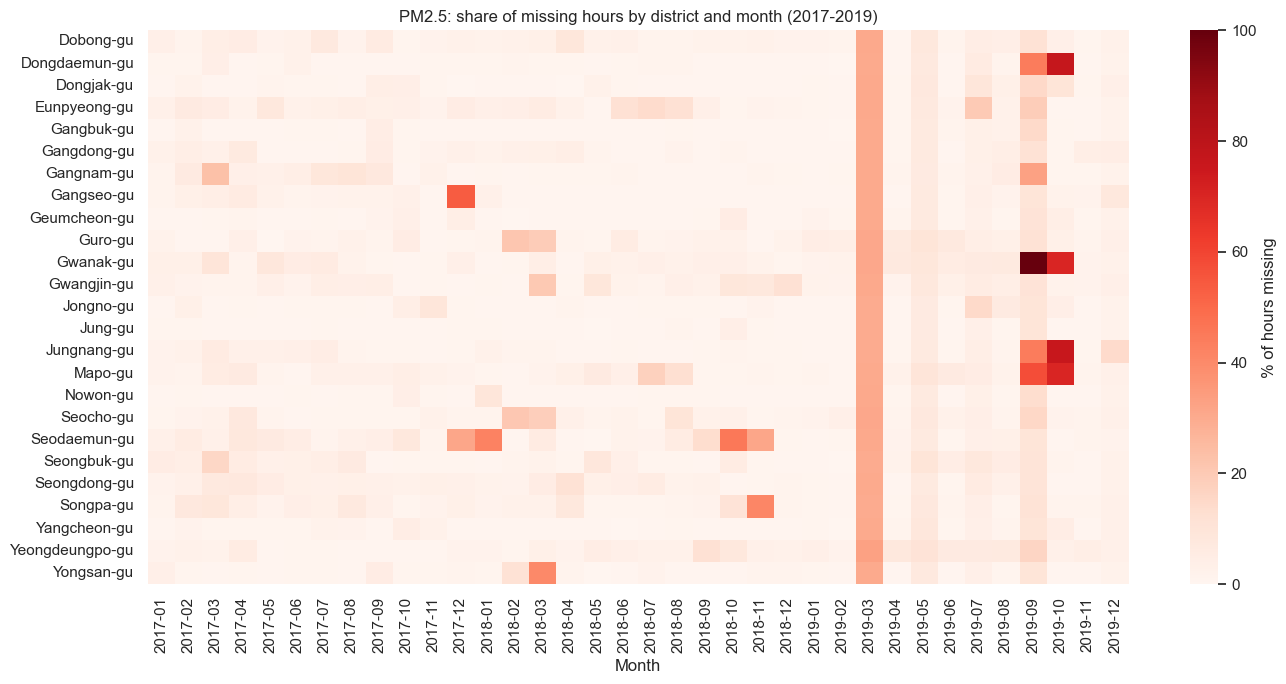

District-months with more than 20% of PM2.5 hours missing: 46 of 900
Worst district-months:
district       month  
Gwanak-gu      2019-09    100.0
Dongdaemun-gu  2019-10     76.6
Jungnang-gu    2019-10     76.2
Gwanak-gu      2019-10     70.2
Mapo-gu        2019-10     70.0


In [16]:
miss = (hourly.assign(month=hourly["datetime"].dt.to_period("M").astype(str))
             .groupby(["district", "month"])["pm25"]
             .apply(lambda s: s.isna().mean() * 100)
             .unstack())
fig, ax = plt.subplots(figsize=(14, 7))
sns.heatmap(miss, cmap="Reds", vmin=0, vmax=100, cbar_kws={"label": "% of hours missing"}, ax=ax)
ax.set_title("PM2.5: share of missing hours by district and month (2017-2019)")
ax.set_xlabel("Month")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(config.FIGURES / "01_missing_pm25.png", dpi=120)
plt.show()
print("District-months with more than 20% of PM2.5 hours missing:", int((miss > 20).sum().sum()), "of", miss.size)
print("Worst district-months:")
print(miss.stack().sort_values(ascending=False).head(5).round(1).to_string())

**Interpretation.** On the complete hourly grid (26,280 hours x 25 stations) between 3.72% (NO2) and 4.96% (PM10) of the hours are missing. Missing data is concentrated: 46 of 900 district-months lose more than 20% of their PM2.5 hours, and Gwanak-gu has no PM2.5 reading at all in September 2019. Section 10 covers the days missing across the whole network. Missing hours are left as missing (no interpolation); daily means use the 18-hour rule below. Because the gaps fall in particular months, district averages can be slightly biased towards the months that were measured (see notebook 03).

## 9. Daily table and Korean grades

A daily mean is computed only when at least 18 of the 24 hourly readings are valid (75% completeness); otherwise the day is left missing. The Korean PM grades (Ministry of Environment) are defined on 24-hour means, so they are added to the daily table only.

In [17]:
daily = daily_means(hourly, pollutants)
daily = daily.merge(stations[["station_code", "district"]], on="station_code", how="left")
daily = daily[["date", "station_code", "district"] + pollutants]
daily["pm25_grade"] = pm_grade(daily["pm25"].round(), "pm25")
daily["pm10_grade"] = pm_grade(daily["pm10"].round(), "pm10")
print("Daily grid:", daily.shape)
daily[pollutants].isna().mean().mul(100).round(2).to_frame("missing_station_days_%")

Daily grid: (27375, 11)


,missing_station_days_%
so2,4.12
no2,3.80
co,4.28
o3,4.09
pm10,4.68
pm25,4.12


### 9.1 Sensitivity to the hour convention

Section 3.1 shows that the timestamps mark the start of each hour, so a calendar day groups 00:00-24:00, as the official daily means do. The check below measures what would change if the labels had been read the other way, as the end of each hour: every reading would move to the hour before, and the 00:00 reading to the previous day.

In [18]:
shifted = hourly.assign(datetime=hourly["datetime"] - pd.Timedelta(hours=1))
end_daily = daily_means(shifted, ["pm25"])
compare = daily[["station_code", "date", "pm25"]].merge(end_daily, on=["station_code", "date"],
                                                         how="left", suffixes=("", "_end"))
pair = compare.dropna(subset=["pm25", "pm25_end"])
change = (pair["pm25_end"] - pair["pm25"]).abs()
grade = pm_grade(pair["pm25"].round(), "pm25")
grade_end = pm_grade(pair["pm25_end"].round(), "pm25")
print(f"Station-days valid under both readings: {len(pair):,}")
print(f"Absolute change of the daily PM2.5 mean (ug/m3): median {change.median():.2f}, "
      f"95th percentile {change.quantile(0.95):.2f}, max {change.max():.2f}")
print(f"Grade changes: {int((grade != grade_end).sum())} ({100 * (grade != grade_end).mean():.1f}%)")
print("Bad-or-worse station-days:", int(grade.isin(["Bad", "Very bad"]).sum()), "->",
      int(grade_end.isin(["Bad", "Very bad"]).sum()))
print("Station-days whose validity changes:", int((compare["pm25"].isna() != compare["pm25_end"].isna()).sum()))

Station-days valid under both readings: 26,211
Absolute change of the daily PM2.5 mean (ug/m3): median 0.35, 95th percentile 1.71, max 6.87
Grade changes: 593 (2.3%)
Bad-or-worse station-days: 4534 -> 4522
Station-days whose validity changes: 54


**Interpretation.** The correct reading changes little for daily statistics. Had the timestamps been read as the end of each hour, the daily PM2.5 mean of a station would move by a median of 0.35 ug/m3 (95th percentile 1.71, at most 6.87); 593 of 26,211 station-days (2.3%) would change grade, the Bad-or-worse station-days would go from 4,534 to 4,522, and 54 station-days would change between valid and missing. Hourly profiles would move by exactly one hour, which matters for statements about rush hours and the ozone peak. The largest risk is a one-hour misalignment when hourly data from another source is joined, which `to_official_label` avoids.

In [19]:
config.DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
hourly.to_parquet(config.DATA_PROCESSED / "air_hourly.parquet", index=False)
daily.to_parquet(config.DATA_PROCESSED / "air_daily.parquet", index=False)
print("Saved:", [p.name for p in sorted(config.DATA_PROCESSED.glob("*.parquet"))])

Saved: ['air_daily.parquet', 'air_hourly.parquet']


## 10. Network-wide gaps

Some days have no valid daily mean at any station, so Seoul as a whole has no value. The table separates days absent from the raw file from days with partial data for the whole network (fewer than 18 hours). `partial_city_mean` is only a reference for those days: it does not meet the completeness rule and is not used in the analysis.

In [20]:
gaps = network_gap_days(daily, hourly)
raw_rows = pm25.groupby(pm25["datetime"].dt.normalize()).size()
gaps["raw_pm25_rows"] = gaps["date"].map(raw_rows).fillna(0).astype(int)
gaps.to_csv(config.METRICS / "01_network_gap_days.csv", index=False)

city_stations = daily.groupby("date")[pollutants].count()
print("Calendar days:", len(city_stations))
print("Days with no valid station, per pollutant:", (city_stations == 0).sum().to_dict())
print("Valid city days for PM2.5:", int((city_stations["pm25"] > 0).sum()))
print("Gap days by year:", gaps["date"].dt.year.value_counts().sort_index().to_dict())
print("Gap days with no raw PM2.5 rows:", int((gaps["raw_pm25_rows"] == 0).sum()))
gaps.round(1)

Calendar days: 1095
Days with no valid station, per pollutant: {'so2': 18, 'no2': 18, 'co': 18, 'o3': 18, 'pm10': 18, 'pm25': 18}
Valid city days for PM2.5: 1077
Gap days by year: {2019: 18}
Gap days with no raw PM2.5 rows: 10


,date,hours_with_data,partial_city_mean,raw_pm25_rows
0,2019-03-09,0,NaN,0
1,2019-03-10,0,NaN,0
2,2019-03-11,4,44.4,83
3,2019-03-12,0,NaN,0
4,2019-03-13,0,NaN,0
5,2019-03-14,0,NaN,0
6,2019-03-15,0,NaN,0
7,2019-03-16,0,NaN,0
8,2019-03-17,0,NaN,0
9,2019-05-16,14,43.9,350


In [21]:
find_runs(city_stations["pm25"] == 0).sort_values("days", ascending=False)

,start,end,days
0,2019-03-09,2019-03-17,9
5,2019-09-07,2019-09-09,3
4,2019-07-03,2019-07-04,2
2,2019-05-18,2019-05-18,1
1,2019-05-16,2019-05-16,1
3,2019-05-22,2019-05-22,1
6,2019-12-01,2019-12-01,1


**Interpretation.** Seoul has no daily value on 18 of the 1,095 calendar days, so 1,077 days are valid. All 18 fall in 2019 and affect the six pollutants at once, a pattern that a fault in one instrument would not produce. Notebook 07 shows that the official OA-15526 file has these days, so they are missing from the Kaggle copy only. On 10 of those days the raw file has no PM2.5 rows; the other 8 keep between 4 and 16 hours for the network, below the 18-hour rule. The longest gap runs from 2019-03-09 to 2019-03-17 (9 days), right after the largest episode of the period; only 2019-03-11 has any data in it, 4 hours with a partial mean of 44.4 ug/m3. Gap days are left missing: they are not interpolated, and later notebooks exclude them from their denominators. Because they all fall in 2019, they mainly affect the 2019 figures and the test year of the forecast.

## 11. Cleaning summary

In [22]:
cleaning = pd.DataFrame([
    {"step": "Raw readings (station x hour x pollutant)", "dropped": 0, "left": n_raw},
    {"step": "Instrument status not normal", "dropped": n_bad_status, "left": n_raw - n_bad_status},
    {"step": "Negative value", "dropped": n_negative, "left": n_raw - n_bad_status - n_negative},
])
cleaning["dropped_%"] = (100 * cleaning["dropped"] / n_raw).round(2)
cleaning

,step,dropped,left,dropped_%
0,Raw readings (station x hour x pollutant),0,3885066,0.00
1,Instrument status not normal,109288,3775778,2.81
2,Negative value,0,3775778,0.00


**Interpretation.** In total 109,288 of 3,885,066 readings (2.81%) were dropped, all because of the instrument status. After the 18-hour completeness rule, 4.12% of the station-days have no valid daily PM2.5 mean, and 18 of the 1,095 days have no valid value for the city.

## 12. Key figures

In [23]:
save_key_figures("01", {
    "readings_raw": n_raw,
    "dropped_pct": 100 * (n_bad_status + n_negative) / n_raw,
    "summary_pm25_above_500": n_summary_extreme,
    "filter_check_station_days": len(grade_base),
    "filter_check_grade_changes": int((grade_base != grade_restored).sum()),
    "gap_days": len(gaps),
    "valid_city_days": int((city_stations["pm25"] > 0).sum()),
    "longest_gap_days": int(find_runs(city_stations["pm25"] == 0)["days"].max()),
})
print((config.METRICS / "01_key_figures.json").read_text())

{
  "dropped_pct": 2.8130281441808194,
  "filter_check_grade_changes": 83,
  "filter_check_station_days": 26247,
  "gap_days": 18,
  "longest_gap_days": 9,
  "readings_raw": 3885066,
  "summary_pm25_above_500": 1063,
  "valid_city_days": 1077
}

